# FD001: từ tín hiệu sensor đến một thời hạn bảo trì

**Học viên:** Phan Nguyễn Mai Phương — **MSHV:** 25002711

Notebook này nối hai loại thông tin: sensor có rời trạng thái ban đầu không, và mô hình RUL dự đoán
còn bao lâu đến khi hỏng. Theo dõi **động cơ train 1** từ tín hiệu gốc qua EWMA và Health Index;
sau đó xem **động cơ test 90** được lên lịch bảo trì tại cycle 147 như thế nào.

EWMA, Health Index, phát hiện bất thường, lưới độ nhạy và lịch được tính lại.
RUL dự đoán lấy từ baseline đã lưu trong repo; nhãn test chỉ đọc sau khi lập lịch.
EWMA dùng cho nhánh Health Index; mô hình RUL giữ bộ features gốc của notebook 03.
Mỗi lần chạy ghi kết quả riêng ở `outputs/notebook06/run-*/`.

**Trong câu chuyện:** cảnh 2 (lọc nhiễu), cảnh 4 (đèn vàng) và cảnh 7 (lịch bảo trì), theo `handoff/STORYLINE.md`; câu hỏi chung là "hôm nay đưa động cơ nào vào xưởng?"

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src/cmapss").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from cmapss.presentation import COLORS, apply_plot_style, style_figure
apply_plot_style()


In [2]:
import tempfile

output_root = ROOT / "outputs/notebook06"
output_root.mkdir(parents=True, exist_ok=True)
OUTPUT = Path(tempfile.mkdtemp(prefix="run-", dir=output_root))
(OUTPUT / "figures").mkdir()
(OUTPUT / "tables").mkdir()

## 1. Làm mượt nhưng chỉ dùng hiện tại và quá khứ

EWMA (trung bình trượt có trọng số mũ) cập nhật theo công thức

$$s_t = \alpha x_t + (1-\alpha)s_{t-1},\quad s_1=x_1,\quad \alpha=\frac{2}{\mathrm{span}+1}.$$

Với span 3, alpha = 0,5. Chuỗi 0, 4, 8 cho kết quả 0, 2, 5.
Đổi điểm cuối thành 999 phải giữ nguyên hai giá trị đã tính trước đó.

In [3]:
from cmapss.degradation import INFORMATIVE_SENSORS, AnomalyConfig, detect_anomalies, ewma_smooth, noise_summary

toy = pd.DataFrame({"engine_id": 1, "cycle": [1, 2, 3], "x": [0.0, 4.0, 8.0]})
smooth_toy = ewma_smooth(toy, ["x"], span=3).x
changed_future = ewma_smooth(toy.assign(x=[0.0, 4.0, 999.0]), ["x"], span=3).x
np.testing.assert_allclose(smooth_toy, [0, 2, 5])
np.testing.assert_allclose(smooth_toy.iloc[:2], changed_future.iloc[:2])
pd.DataFrame({"x": toy.x, "EWMA": smooth_toy, "EWMA_after_changing_future": changed_future})

,x,EWMA,EWMA_after_changing_future
0,0.0,0.0,0.0
1,4.0,2.0,2.0
2,8.0,5.0,500.5


Với dữ liệu thật, span = 10 tương ứng alpha khoảng 0,18: giá trị mới chiếm khoảng 18%,
phần còn lại lấy từ giá trị đã làm mượt. Áp dụng riêng từng động cơ cho 14 sensor có xu hướng;
bảy sensor còn lại gần như hằng.

Độ lệch chuẩn của sai phân giữa hai cycle liền kề được dùng để đo mức giảm dao động.

In [4]:
from cmapss.data.readers import read_observations

train = read_observations(ROOT / "data/raw/train_FD001.txt", split="train")
test = read_observations(ROOT / "data/raw/test_FD001.txt", split="test")
assert train.engine_id.nunique() == test.engine_id.nunique() == 100
smoothed = ewma_smooth(train, INFORMATIVE_SENSORS, span=10)
noise = noise_summary(train, smoothed, INFORMATIVE_SENSORS)
noise.round(4)

,sensor,diff_std_raw,diff_std_smoothed,reduction_pct
0,sensor_2,0.4270,0.0583,86.3422
1,sensor_3,5.6575,0.7715,86.3635
2,sensor_4,5.6994,0.7829,86.2626
3,sensor_7,0.5773,0.0789,86.3367
4,sensor_8,0.0428,0.0060,86.0672
5,sensor_9,5.9037,0.9241,84.3473
6,sensor_11,0.1436,0.0198,86.1785
7,sensor_12,0.4245,0.0588,86.1550
8,sensor_13,0.0430,0.0060,86.0069
9,sensor_14,4.4532,0.7285,83.6408


Sau EWMA, dao động ngắn hạn giảm khoảng 86% ở hầu hết sensor.
Mức giảm thấp nhất ở sensor 14 (83,6%) và sensor 9 (84,3%).
Dữ liệu không có tín hiệu sạch để xác nhận phần đã giảm hoàn toàn là nhiễu đo.

Xem động cơ train 1: đường làm mượt có còn giữ được chiều tăng của sensor 11 và 4 không?

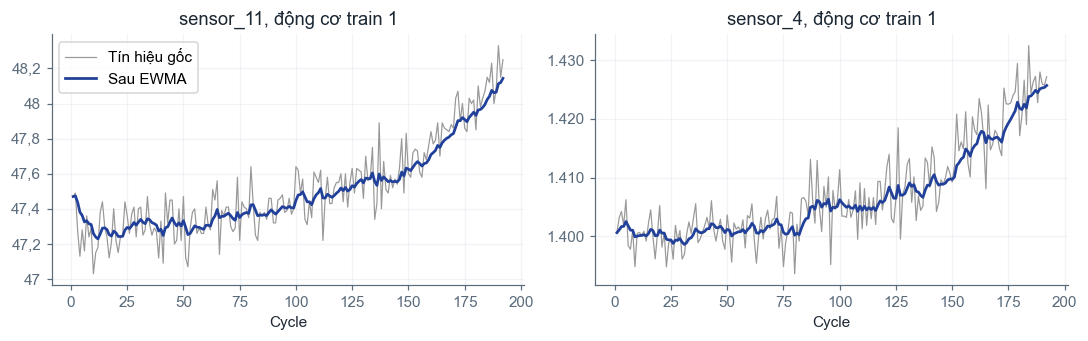

In [5]:
engine = 1
raw_engine = train[train["engine_id"] == engine]
smooth_engine = smoothed[smoothed["engine_id"] == engine]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, sensor in zip(axes, ["sensor_11", "sensor_4"]):
    ax.plot(raw_engine["cycle"], raw_engine[sensor], color="0.6", linewidth=0.8, label="Tín hiệu gốc")
    ax.plot(smooth_engine["cycle"], smooth_engine[sensor], color=COLORS["blue"], linewidth=1.8, label="Sau EWMA")
    ax.set(title=f"{sensor}, động cơ train {engine}", xlabel="Cycle")
axes[0].legend()
plt.tight_layout()
style_figure(fig)
fig.savefig(OUTPUT / "figures/engine1_ewma.png", dpi=150)
style_figure(fig)
display(fig)
plt.close(fig)

Ở động cơ train 1, hỏng tại cycle 192, tín hiệu sau EWMA vẫn giữ xu hướng tăng của `sensor_11`
và `sensor_4`, đặc biệt từ cycle 150, đồng thời giảm các dao động ngắn.
Con số 86% chỉ đo mức giảm dao động. Dữ liệu không có tín hiệu sạch để xác nhận EWMA đã loại đúng nhiễu đo.

## 2. Từ nhiều sensor đến một mức thay đổi so với ban đầu

StandardScaler chuẩn hóa 21 sensor, gồm 14 sensor đã làm mượt. PCA chiếu về **một thành phần PC1**;
chọn dấu giảm theo cycle rồi chuẩn hóa PC1. Bước này không dùng nhãn RUL.

Ở đây, transformer học từ toàn bộ 100 động cơ train để áp dụng cho test.
Notebook 04 có giao thức khác: loại 10 động cơ dự báo khỏi bước học transformer.
Hai Health Index vì vậy cần được diễn giải theo đúng cách fit của từng bài toán.

In [6]:
from cmapss.timeseries.health_index import fit_health_index

fitted_train = fit_health_index(smoothed)
health_index = fitted_train.health_index
config = AnomalyConfig()
events = detect_anomalies(health_index, config, column="health_index")
leads = events.lead_cycles.astype(float)
events[["engine_id", "detection_cycle", "lead_cycles"]].head()

,engine_id,detection_cycle,lead_cycles
0,1,84,108
1,2,72,215
2,3,64,115
3,4,77,112
4,5,86,183


Với từng động cơ, lấy trung bình $\mu_i$ và độ lệch chuẩn mẫu $\sigma_i$ từ 30 cycle đầu.
Tính $z_{i,t}=(h_{i,t}-\mu_i)/\sigma_i$. Xác nhận bất thường khi $z\le-3$ đủ **5 cycle liên tiếp**;
thời điểm phát hiện là cycle thứ năm của chuỗi đó.

Bảng sau xem các cycle quanh thời điểm phát hiện của động cơ train 1 để đối chiếu quy tắc.

In [7]:
event = events.set_index("engine_id").loc[engine]
curve = health_index.loc[health_index.engine_id.eq(engine)].copy()
curve["z"] = (curve.health_index - event.baseline_mean) / event.baseline_std
detection = int(event.detection_cycle)
detail = curve.loc[curve.cycle.between(detection - 6, detection), ["cycle", "health_index", "z"]]
assert detail.tail(config.persistence).z.le(-config.z_threshold).all()
detail.assign(below_threshold=detail.z.le(-config.z_threshold)).round(4)

,cycle,health_index,z,below_threshold
77,78,0.7920,-2.1052,False
78,79,0.7548,-2.6449,False
79,80,0.7280,-3.0348,True
80,81,0.6891,-3.6004,True
81,82,0.7005,-3.4345,True
82,83,0.6799,-3.7342,True
83,84,0.6325,-4.4225,True


Động cơ train 1 có mức tham chiếu trung bình 0,937 và std 0,069.
Ngưỡng HI là $0,937-3\times0,069\approx0,730$. Tín hiệu được xác nhận ở cycle 84;
động cơ hỏng tại cycle 192 nên còn 108 cycle, tức phát hiện ở khoảng 44% vòng đời.

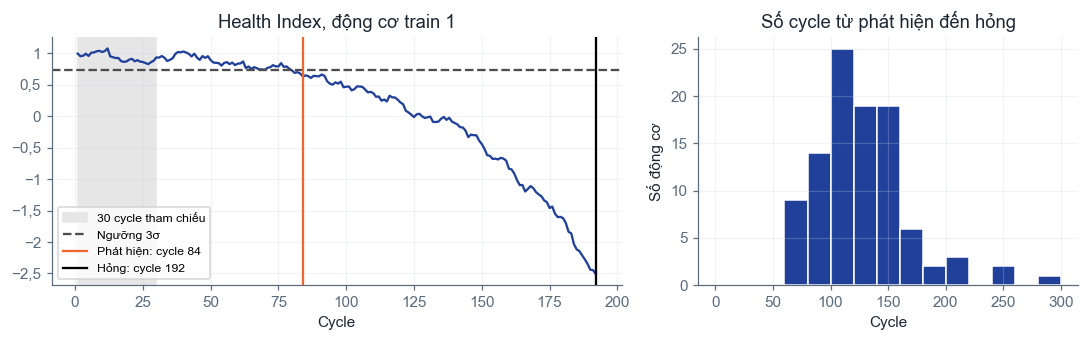

In [8]:
event = events.set_index("engine_id").loc[engine]
curve = health_index[health_index["engine_id"] == engine]
threshold = event["baseline_mean"] - config.z_threshold * event["baseline_std"]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1.5, 1]})
left.plot(curve["cycle"], curve["health_index"], color=COLORS["blue"])
left.axvspan(1, config.baseline_cycles, color="0.9", label="30 cycle tham chiếu")
left.axhline(threshold, color="0.3", linestyle="--", label="Ngưỡng 3σ")
left.axvline(event["detection_cycle"], color=COLORS["orange"], label=f"Phát hiện: cycle {int(event['detection_cycle'])}")
left.axvline(event["failure_cycle"], color="black", label=f"Hỏng: cycle {int(event['failure_cycle'])}")
left.set(title=f"Health Index, động cơ train {engine}", xlabel="Cycle")
left.legend(fontsize=8)
right.hist(leads, bins=range(0, int(leads.max()) + 20, 20), color=COLORS["blue"], edgecolor="white")
right.set(title="Số cycle từ phát hiện đến hỏng", xlabel="Cycle", ylabel="Số động cơ")
plt.tight_layout()
style_figure(fig)
fig.savefig(OUTPUT / "figures/engine1_anomaly.png", dpi=150)
style_figure(fig)
display(fig)
plt.close(fig)

Cả 100 động cơ train được phát hiện trước khi hỏng; thời gian báo trước có trung vị 121 cycle,
nhỏ nhất 67 cycle. Đây là thống kê trên train để mô tả quy tắc.

Cần xem EWMA có làm ngưỡng thay đổi không. Tính lại cùng quy tắc trên Health Index từ tín hiệu gốc.

In [9]:
raw_health_index = fit_health_index(train).health_index
events_raw = detect_anomalies(raw_health_index, config, column="health_index")
comparison = pd.DataFrame({
    "median_lead_cycles": [leads.median(), events_raw.lead_cycles.astype(float).median()],
    "median_life_fraction_pct": [
        (events.detection_cycle / events.failure_cycle).median() * 100,
        (events_raw.detection_cycle / events_raw.failure_cycle).median() * 100,
    ],
}, index=["EWMA", "raw"])
comparison.round(1)

,median_lead_cycles,median_life_fraction_pct
EWMA,121.0,39.1
raw,72.5,61.7


Với tín hiệu gốc, thời gian báo trước có trung vị 72,5 cycle, tương ứng khoảng 62% vòng đời lúc phát hiện.
Sau khử nhiễu, hai giá trị lần lượt là 121 cycle và 39%. Tín hiệu gốc dao động mạnh hơn trong
30 cycle tham chiếu, làm $\sigma_i$ lớn hơn và ngưỡng $3\sigma$ nằm xa mức trung bình hơn.

Dữ liệu train chỉ ghi thời điểm hỏng, không có nhãn bắt đầu suy giảm, nên chưa tính được tỷ lệ báo động giả.
Báo sớm hơn vì vậy chưa đủ để kết luận chất lượng cảnh báo tốt hơn. Quy tắc này được dùng cho cảnh báo
mức 1: phát hiện động cơ rời trạng thái ổn định ban đầu, chưa ước lượng thời gian còn lại.

## 3. Ngưỡng và số cycle liên tiếp ảnh hưởng thế nào?

Tính lại lưới z = 2, 3, 4 và persistence = 3, 5, 10, trên cả tín hiệu gốc và EWMA.
Các tham số 3 sigma/5 cycle được giữ như cấu hình đã chọn trước.

`n_early` đếm cảnh báo trong cycle 31–40, ngay sau đoạn tham chiếu. Ví dụ, giá trị 1
nghĩa là một động cơ được báo trong khoảng đó. Đây là chỉ số mô tả độ nhạy;
dữ liệu chưa có nhãn bắt đầu suy giảm để xác định các cảnh báo này đúng hay nhầm.

In [10]:
from cmapss.degradation.anomaly import sensitivity_grid

ewma_grid = sensitivity_grid(health_index, column="health_index")
raw_grid = sensitivity_grid(raw_health_index, column="health_index")
grid = pd.concat([ewma_grid.assign(signal="ewma"), raw_grid.assign(signal="raw")], ignore_index=True)
ewma_grid[["z_threshold", "persistence", "n_detected", "lead_min", "lead_median", "n_early"]]

,z_threshold,persistence,n_detected,lead_min,lead_median,n_early
0,2.0,3,100,78.0,136.0,17
1,2.0,5,100,76.0,132.5,8
2,2.0,10,100,71.0,124.0,0
3,3.0,3,100,77.0,127.0,2
4,3.0,5,100,67.0,121.0,1
5,3.0,10,100,62.0,110.5,0
6,4.0,3,100,62.0,114.5,1
7,4.0,5,100,60.0,109.0,1
8,4.0,10,100,50.0,98.5,0


In [11]:
ewma_grid.pivot(index="z_threshold", columns="persistence", values=["lead_median", "n_early"])

lead_median               n_early          
persistence          3      5      10      3    5    10
z_threshold                                            
2.0               136.0  132.5  124.0    17.0  8.0  0.0
3.0               127.0  121.0  110.5     2.0  1.0  0.0
4.0               114.5  109.0   98.5     1.0  1.0  0.0

Cả 9 cấu hình EWMA phát hiện đủ 100/100 động cơ. Ở 2 sigma/3 cycle, có 17 động cơ được báo
trong cycle 31–40; tăng persistence lên 5 còn 8. Ở 4 sigma/10 cycle, không có ca trong khoảng này,
nhưng trung vị báo trước giảm còn 98,5 cycle và ca muộn nhất còn 50 cycle.

Cấu hình 3 sigma/5 cycle có 1 ca trong cycle 31–40, trung vị báo trước 121 và nhỏ nhất 67 cycle.
So với 2 sigma/3 cycle, trung vị giảm 15 cycle và số ca trong khoảng đầu giảm 16.
Với 3 sigma/10 cycle, số ca đầu bằng 0 và trung vị giảm thêm khoảng 10 cycle.

Trên tín hiệu gốc, lưới không có ca trong cycle 31–40, nhưng trung vị báo trước chỉ 52–103 cycle.
Các số này thể hiện đánh đổi của ngưỡng, chưa đo được tỷ lệ báo động giả.

## 4. Từ RUL dự đoán đến thời hạn bảo trì của động cơ test 90

Gọi $t_i$ là cycle quan sát cuối và $\hat y_i$ là RUL dự đoán.
Với khoảng dự phòng 30 cycle:

$$c_i=\max(\lfloor\hat y_i-30\rfloor,0),\qquad m_i=t_i+c_i.$$

$c_i$ là số cycle đến hạn, $m_i$ là cycle bảo trì.
Xét trạng thái theo thứ tự: **Cần bảo trì** khi RUL dự đoán ≤ 30;
**Theo dõi tăng cường** nếu HI đã báo bất thường; còn lại **Bình thường**.

Test dùng scaler/PCA đã fit trên train. Động cơ dưới 35 cycle chưa đủ 30 cycle tham chiếu
và 5 cycle liên tiếp để xét bất thường; RUL dự đoán vẫn dùng để xác định trạng thái.

In [12]:
from cmapss.maintenance import (
    STATUS_ORDER, MaintenanceConfig, anomaly_status, build_schedule, transform_health_index,
)

test_smoothed = ewma_smooth(test, INFORMATIVE_SENSORS, span=10)
test_health_index = transform_health_index(fitted_train, test_smoothed)
anomalies = anomaly_status(test_health_index, config)
PREDICTION_PATH = ROOT / "outputs/modeling/predictions/final_predictions.parquet"
predictions = pd.read_parquet(PREDICTION_PATH)
maintenance_config = MaintenanceConfig()
schedule = build_schedule(predictions, anomalies, maintenance_config)
schedule.query("engine_id == 90")[
    ["engine_id", "current_cycle", "rul_pred", "anomaly_cycle", "cycles_to_maintenance", "maintenance_cycle", "status"]
]

,engine_id,current_cycle,rul_pred,anomaly_cycle,cycles_to_maintenance,maintenance_cycle,status
21,90,146,31.219069,67,1,147,Theo dõi tăng cường


Động cơ test 90 có cycle hiện tại 146, RUL dự đoán khoảng 31,2 và đã báo bất thường từ cycle 67.
Do 31,2 > 30, trạng thái là Theo dõi tăng cường. Thời hạn bảo trì:
$\lfloor31,2-30\rfloor=1$ cycle, tức cycle 147.

Bảng nhỏ trên tách **trạng thái hiện tại** khỏi **thời hạn bảo trì**.
Mở rộng cùng quy tắc cho cả đội động cơ để phân bổ công việc.

In [13]:
pd.Series(schedule.status.value_counts().reindex(STATUS_ORDER), name="engines")

status
Cần bảo trì            21
Theo dõi tăng cường    59
Bình thường            20
Name: engines, dtype: int64

In [14]:
schedule[["engine_id", "current_cycle", "rul_pred", "cycles_to_maintenance", "maintenance_cycle", "status"]].head(10)

,engine_id,current_cycle,rul_pred,cycles_to_maintenance,maintenance_cycle,status
0,34,203,6.178904,0,203,Cần bảo trì
1,81,213,6.671042,0,213,Cần bảo trì
2,76,205,6.896508,0,205,Cần bảo trì
3,31,196,8.103197,0,196,Cần bảo trì
4,68,187,8.795637,0,187,Cần bảo trì
5,49,303,9.074799,0,303,Cần bảo trì
6,20,184,9.873178,0,184,Cần bảo trì
7,82,162,10.621104,0,162,Cần bảo trì
8,35,198,13.908740,0,198,Cần bảo trì
9,56,136,14.476055,0,136,Cần bảo trì


Lịch có 21 động cơ Cần bảo trì, 59 động cơ Theo dõi tăng cường và 20 động cơ Bình thường.
Mười dòng đầu có RUL dự đoán dưới 15 cycle, nên lịch yêu cầu bảo trì ngay ($c_i = 0$).
Động cơ 1 và 85 chỉ có 31 và 34 cycle, chưa đủ đánh giá bất thường; trạng thái của chúng
được xác định từ RUL dự đoán.

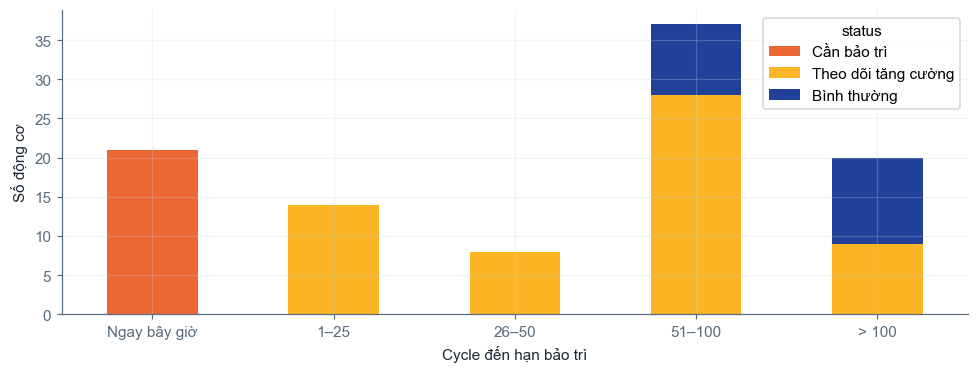

status,Cần bảo trì,Theo dõi tăng cường,Bình thường
Ngay bây giờ,21,0,0
1–25,0,14,0
26–50,0,8,0
51–100,0,28,9
> 100,0,9,11


In [15]:
windows = {"Ngay bây giờ": (0, 0), "1–25": (1, 25), "26–50": (26, 50),
           "51–100": (51, 100), "> 100": (101, 10_000)}
planning = pd.DataFrame({
    label: schedule.loc[schedule.cycles_to_maintenance.between(low, high), "status"]
                   .value_counts().reindex(STATUS_ORDER, fill_value=0)
    for label, (low, high) in windows.items()
}).T
ax = planning.plot(kind="bar", stacked=True, color=[COLORS["orange"], COLORS["gold"], COLORS["blue"]],
                   figsize=(9, 3.5), rot=0, xlabel="Cycle đến hạn bảo trì", ylabel="Số động cơ")
fig = ax.figure
fig.tight_layout()
style_figure(fig)
fig.savefig(OUTPUT / "figures/maintenance_plan.png", dpi=150)
style_figure(fig)
display(fig)
plt.close(fig)
planning

Có 21 động cơ cần bảo trì ngay, 14 động cơ đến hạn trong 25 cycle tới và 8 động cơ đến hạn
trong khoảng 26–50 cycle. Hai nhóm đến hạn sau đều thuộc trạng thái Theo dõi tăng cường.
Còn 57 động cơ có thời hạn trên 50 cycle.

Nếu mỗi đợt chỉ xử lý được vài động cơ, đội bảo trì cần chuẩn bị cho khoảng 35 động cơ
trong 25 cycle đầu tiên.

## 5. Lập xong lịch mới đối chiếu với nhãn test

Đến đây mới đọc `RUL_FD001.txt`. Một động cơ thực sự cần bảo trì ngay theo ngưỡng minh họa
khi RUL thật ≤ 30. Bảng chéo đối chiếu trạng thái đã lập với RUL thật; nhãn này không được dùng
để thay quy tắc sau khi xem kết quả.

In [16]:
from cmapss.data.readers import read_test_labels
from cmapss.maintenance import evaluate_schedule

labels = read_test_labels(ROOT / "data/raw/RUL_FD001.txt")
crosstab, evaluation = evaluate_schedule(schedule, labels, maintenance_config)
crosstab

actual_rul,≤ 30,31–60,> 60
status,,,
Cần bảo trì,21,0,0
Theo dõi tăng cường,4,14,41
Bình thường,0,0,20


In [17]:
pd.Series({
    "actual_needs_maintenance": evaluation["n_actual_needs_maintenance"],
    "flagged_needs_maintenance": evaluation["n_flagged_needs_maintenance"],
    "correctly_flagged": evaluation["n_correct_needs_maintenance"],
    "flagged_above_actual_threshold": evaluation["n_flagged_but_actual_above_threshold"],
    "cycles_to_maintenance_MAE": evaluation["cycles_to_maintenance_mae"],
})

actual_needs_maintenance          25.00
flagged_needs_maintenance         21.00
correctly_flagged                 21.00
flagged_above_actual_threshold     0.00
cycles_to_maintenance_MAE         14.21
dtype: float64

Cả 21 động cơ thuộc nhóm Cần bảo trì đều có RUL thật ≤ 30, không có ca báo nhầm trong nhóm này.
Trong 25 động cơ thực sự cần bảo trì, 4 động cơ còn lại thuộc nhóm Theo dõi tăng cường.
Nhóm Bình thường không có động cơ nào với RUL thật dưới 60.

Nhóm Theo dõi tăng cường còn khá rộng: 41 trong 59 động cơ vẫn còn trên 60 cycle.

In [18]:
check = schedule.merge(labels[["engine_id", "rul"]], on="engine_id")
check[(check["rul"] <= 30) & (check["status"] != STATUS_ORDER[0])][
    ["engine_id", "current_cycle", "rul_pred", "cycles_to_maintenance", "rul", "status"]
]

,engine_id,current_cycle,rul_pred,cycles_to_maintenance,rul,status
21,90,146,31.219069,1,28,Theo dõi tăng cường
22,37,121,31.363663,1,21,Theo dõi tăng cường
25,18,133,37.375699,7,28,Theo dõi tăng cường
26,40,133,38.459289,8,28,Theo dõi tăng cường


Bốn động cơ 90, 37, 18, 40 có RUL dự đoán 31–38, cao hơn ngưỡng 30 một ít,
trong khi RUL thật là 21–28. Lịch yêu cầu bảo trì sau 1–8 cycle, vẫn trước thời điểm hỏng thật.
Ví dụ, động cơ 90 được lên lịch tại cycle 147 và hỏng ở cycle 146 + 28 = 174.

Một lịch xa vẫn có thể trễ nếu RUL bị dự đoán quá cao. Kiểm tra cycle bảo trì đã chốt
so với cycle hỏng suy ra từ nhãn test.

In [19]:
check["actual_failure_cycle"] = check.current_cycle + check.rul
check["schedule_delay_cycles"] = check.maintenance_cycle - check.actual_failure_cycle
late_schedule = check.loc[check.schedule_delay_cycles.gt(0)]
display(late_schedule[["engine_id", "current_cycle", "rul_pred", "rul", "schedule_delay_cycles"]])
assert len(schedule) == schedule.engine_id.nunique() == 100
assert len(ewma_grid) == len(raw_grid) == 9

,engine_id,current_cycle,rul_pred,rul,schedule_delay_cycles
61,50,74,113.307109,79,4
73,54,121,136.643968,97,9
75,88,68,155.568590,115,10
76,65,71,167.186818,128,9
77,23,130,170.476835,113,27
78,83,73,181.674017,137,14
79,73,112,184.286377,131,23
89,67,71,131.251560,77,24
92,2,49,135.630832,98,7
94,78,72,143.008312,107,6


Có 12 lịch muộn hơn thời điểm hỏng từ 4 đến 27 cycle; cả 12 động cơ có RUL thật ít nhất 77 cycle.
Ví dụ động cơ train 23 được dự đoán còn khoảng 170 cycle, thực tế còn 113. Lịch ghi cycle 270,
muộn hơn cycle hỏng thật 243.

Vì vậy, cần tính lại lịch khi có dữ liệu mới. Mốc dự phòng 30 cycle vẫn là lựa chọn minh họa,
chưa được hiệu chỉnh theo chi phí bảo trì.

## 6. Lưu kết quả và điều kiện chạy

Lưu các bảng vừa tính để kiểm tra lại từ tín hiệu đã làm mượt đến lịch và bước đánh giá cuối.

In [20]:
tables = {"noise_summary": noise, "anomaly_events": events, "anomaly_sensitivity": grid,
          "maintenance_schedule": schedule, "planning": planning.reset_index(),
          "test_evaluation": check, "crosstab": crosstab.reset_index()}
for name, table in tables.items():
    table.to_csv(OUTPUT / f"tables/{name}.csv", index=False)
import json
import hashlib

sources = [ROOT / "data/raw/train_FD001.txt", ROOT / "data/raw/test_FD001.txt", PREDICTION_PATH]
run_info = {
    "author": "Phan Nguyễn Mai Phương", "student_id": "25002711",
    "EWMA_span": 10, "baseline_cycles": 30, "z_threshold": 3, "persistence": 5,
    "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in sources},
    "evaluation": evaluation,
}
(OUTPUT / "run_info.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Kết quả lần chạy: {OUTPUT.relative_to(ROOT)}")

Kết quả lần chạy: outputs\notebook06\run-0z2uh7pw


động cơ train 1 minh họa cách một tín hiệu được làm mượt rồi chuyển thành cảnh báo lệch khỏi trạng thái ban đầu.
động cơ train 90 minh họa cách RUL dự đoán và bất thường cùng quyết định trạng thái và thời hạn.

Lịch hiện tại gắn cờ Cần bảo trì đúng cho 21/25 động cơ thực sự ở vùng RUL ≤ 30.
Bốn động cơ còn lại được xếp Theo dõi tăng cường và lên lịch trước lúc hỏng,
nhưng các lịch xa vẫn có ca trễ. Đây là các giới hạn cần giữ khi diễn giải kết quả.